In [53]:
import numpy as np
iris = np.genfromtxt('data/iris_1D.csv', delimiter=',', skip_header=1)
X = iris[:, :1]
Y = iris[:, 1]
intercept = np.ones((X.shape[0], 1))

X = np.concatenate((intercept, X), axis = 1)
print(X)

[[1.  1.4]
 [1.  1. ]
 [1.  1.5]
 [1.  3. ]
 [1.  3.8]
 [1.  4.1]]


In [61]:
print(Y)

[0. 0. 0. 1. 1. 1.]


In [54]:
theta = np.array([0.1, -0.1])
lr = 0.1
losses = []

def predict(x, theta):
    z = x.T.dot(theta)
    y_hat = 1 / (1 + np.exp(-z))
    return y_hat

def compute_loss(y_hat, y):
    loss = -1 * (y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
    return loss

def compute_gradient(x, y_hat, y):
    return x * (y_hat - y)


def update(theta, gradient, lr):
    theta = theta - lr * gradient
    return theta


In [55]:

for _ in range(100):
    # for each sample:
    for i in range(len(X)):
        x = X[i, :]
        y = Y[i]

        y_hat = predict(x, theta)

        loss = compute_loss(y_hat, y)
        losses.append(loss)
        gradient = compute_gradient(x, y_hat, y)
        theta = update(theta, gradient, lr)

print(theta)
        

[-4.52690827  2.11002392]


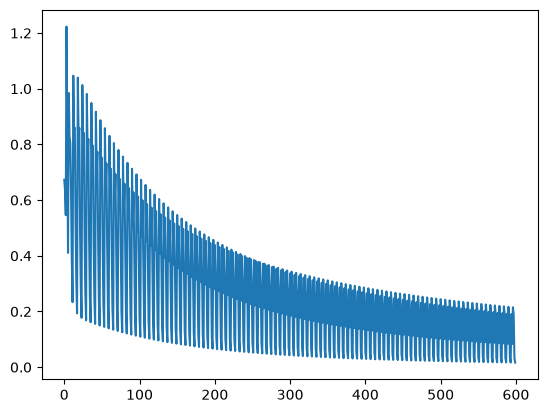

In [56]:
import matplotlib.pyplot as plt
plt.plot(losses)

In [62]:
preds = []
for i in range(len(X)):
    x = X[i, :]
    y = Y[i]
    y_hat = predict(x, theta)
    preds.append(y_hat)

(Y == np.array(preds).round()).mean()

np.float64(1.0)